# Is the 60/40 Portfolio Still Diversified? (data to 11/20/2026)

**Question:** Do US bonds still diversify an equity portfolio, or have stocks and bonds started moving together?

**Short answer (original 2004–2024 study):** Over 2004–2024 as a whole, daily stock and bond returns look unrelated (correlation ≈ 0). That average hides two opposite regimes. Before 2020 the correlation was mostly **negative**, so bonds cushioned equity drawdowns. Since 2020 it has been mostly **positive**, so bonds and stocks have tended to fall together, which weakens the diversification a 60/40 portfolio relies on.

| | |
|---|---|
| **Equities** | SPY (S&P 500 ETF), total return (prices adjusted for dividends) |
| **Bonds** | AGG (iShares Core US Aggregate Bond ETF), total return |
| **Period** | AGG inception (late 2003) to the most recent trading day |
| **Source** | Yahoo Finance via `yfinance` |
| **Tools** | Python, pandas, statsmodels, matplotlib, seaborn |

This version extends the original study (data through December 31, 2024) to the most recent trading day, and adds a check on 2025 onward to test whether the post-2020 regime has persisted.

## Summary

### How I approached it
1. **Start with the simple test.** Regress stock returns on bond returns over the whole period. In the original 2004–2024 study, this showed no relationship on daily data but a positive one on monthly data. Those two answers disagree, which suggested the relationship was not stable over time.
2. **Check whether the relationship changed over time.** Plot rolling correlations. The 3-month window shows when the sign changes, and the 6-month and 1-year windows show whether the change lasts. All point to a flip from negative to positive in early 2020.
3. **Test the shift formally.** Split the sample at 2020 and rerun the regression for each period, on both daily and monthly returns, with standard errors that account for volatile, autocorrelated returns.
4. **Interpret the horizon.** Compare daily and monthly results to see where the effect is strongest, since a 60/40 investor rebalances and measures risk over months, not days.

### What I found

| | 2004–2019 | 2020–Nov 2026 | 2025–Nov 2026 (out of sample) |
|---|---|---|---|
| Daily correlation | -0.12 (p = 0.11) | **+0.18** (p < 0.001) | **+0.18** (p = 0.005) |
| Monthly correlation | 0.00 (p = 0.97) | **+0.50** (p < 0.001) | +0.13 (p = 0.21) |
| Monthly R-squared | 0.00 | **0.25** | 0.02 |

- **The post-2020 regime has held up.** With almost two more years of data, stocks and bonds still move together since 2020: daily +0.18 and monthly +0.50, both significant at p < 0.001.
- **It persists out of sample on daily data.** In 2025 to November 2026, a period the original study never saw, the daily correlation is +0.18 (p = 0.005), almost identical to the full post-2020 period.
- **The monthly link has weakened recently.** The 2025–2026 monthly correlation is +0.13 and not significant, down from +0.57 in 2020–2024. With only 23 monthly observations this is inconclusive, but it is consistent with inflation becoming less dominant as a shared driver. Worth watching.
- **The full-period picture is unchanged.** Over 2004 to November 2026, daily correlation is about zero (p = 0.98) and monthly is +0.23 (p = 0.002), because the two regimes still cancel out on daily data.

### Method choices
- **Data:** SPY and AGG adjusted closes (total returns). Positive correlation means stocks and bonds moved in the same direction.
- **Regression:** OLS of SPY returns on AGG returns. Standard errors are HAC (Newey-West), which corrects for changing volatility and autocorrelation in returns, so significance is not overstated.
- **Regime split at 2020:** chosen from the rolling correlations, which show the break there. A formal structural-break test is listed as a next step.
- **Rolling windows count trading days** (about 252 a year): 63 days ≈ 3 months, 126 ≈ 6 months, 252 ≈ 1 year. A correlation's sampling error is roughly 1/√n, so 63 days (about ±0.13) is the shortest window precise enough to tell +0.2 from zero, while 252 days (about ±0.06) is stable but slower. Using three windows checks that the result does not depend on the window chosen.

## Method

1. **Data:** download adjusted daily closes for SPY and AGG and compute daily and month-end returns.
2. **Full-period regression:** regress equity returns on bond returns (OLS with heteroskedasticity- and autocorrelation-robust standard errors).
3. **Rolling correlation:** 63-day (~3 months), 126-day (~6 months), and 252-day (~1 year) windows to show how the relationship changes over time.
4. **Regime regressions:** repeat the regression separately for 2004–2019, 2020 to date, and 2025 to date, on daily and monthly data.

## Install packages

Run once per session (needed in Colab; skip if the packages are already installed).

In [1]:
!pip install -q yfinance statsmodels seaborn

## Setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.api as sm
import yfinance as yf

START = "2003-09-29"   # AGG began trading in late September 2003
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")   # through the latest trading day
RECENT = "2025-01-01"   # start of the out-of-sample check
REGIME_BREAK = "2020-01-01"
sns.set_theme(style="white")

## 1. Data

In [3]:
prices = yf.download(["SPY", "AGG"], start=START, end=END, auto_adjust=True, progress=False)["Close"]
prices = prices.rename(columns={"SPY": "Equities", "AGG": "Bonds"})[["Equities", "Bonds"]].dropna()

daily = prices.pct_change().dropna()
monthly = prices.resample("ME").last().pct_change().dropna()

print(f"Daily observations:   {len(daily):,}  ({daily.index.min().date()} to {daily.index.max().date()})")
print(f"Monthly observations: {len(monthly):,}")

Daily observations:   5,824  (2003-09-30 to 2026-11-20)
Monthly observations: 278


## 2. Full-period regression

In [4]:
def regress(df, label):
    X = sm.add_constant(df["Bonds"])
    res = sm.OLS(df["Equities"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    return {"Sample": label, "Obs": int(res.nobs), "Beta": res.params["Bonds"],
            "t-stat": res.tvalues["Bonds"], "p-value": res.pvalues["Bonds"],
            "R-squared": res.rsquared, "Correlation": df["Equities"].corr(df["Bonds"])}

full = pd.DataFrame([regress(daily, "Daily, full period"), regress(monthly, "Monthly, full period")]).set_index("Sample")
full.round(3)

,Obs,Beta,t-stat,p-value,R-squared,Correlation
Sample,,,,,,
"Daily, full period",5824,-0.004,-0.031,0.975,0.000,-0.001
"Monthly, full period",278,0.737,3.068,0.002,0.051,0.225


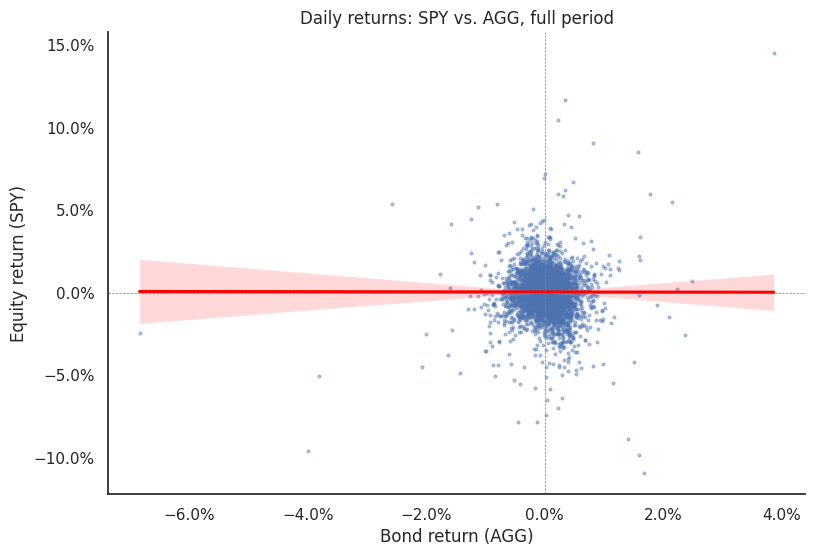

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(x="Bonds", y="Equities", data=daily, scatter_kws={"s": 4, "alpha": 0.4}, line_kws={"color": "red"}, ax=ax)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.axhline(0, color="gray", lw=0.5, ls="--"); ax.axvline(0, color="gray", lw=0.5, ls="--")
ax.set(title="Daily returns: SPY vs. AGG, full period", xlabel="Bond return (AGG)", ylabel="Equity return (SPY)")
sns.despine(); plt.show()

Over the full period the slope is close to zero and not statistically significant. The next section shows why: the relationship changed sign, and the two regimes cancel out in a single regression.

## 3. Rolling correlation

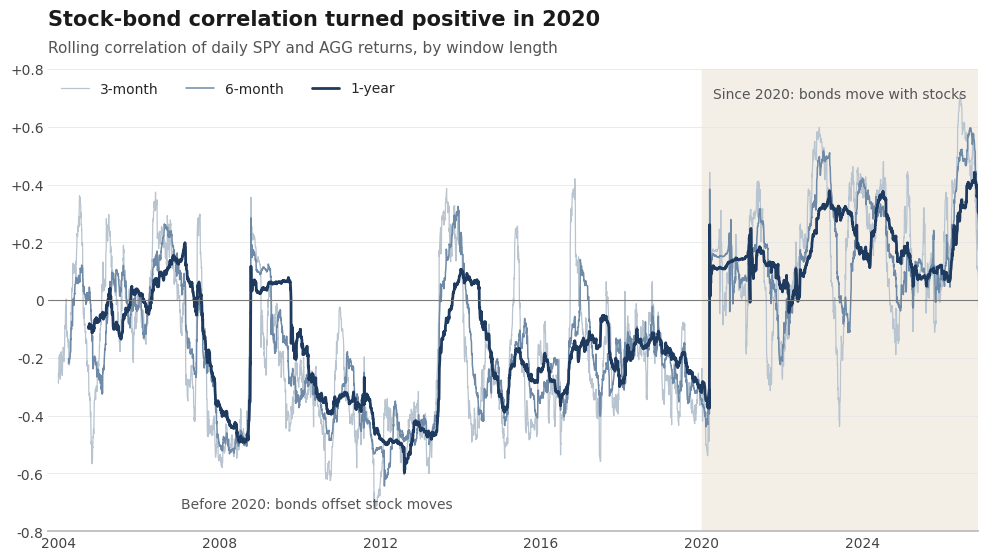

In [6]:
windows = [(63, "3-month", "#B8C4D0", 0.9), (126, "6-month", "#6F8AA6", 1.1), (252, "1-year", "#1F3A5F", 2.0)]
break_date = pd.Timestamp(REGIME_BREAK)

fig, ax = plt.subplots(figsize=(12, 6))
ax.axvspan(break_date, daily.index.max(), color="#F3EFE7", zorder=0)
for window, label, color, lw in windows:
    ax.plot(daily["Equities"].rolling(window).corr(daily["Bonds"]), color=color, lw=lw, label=label)

ax.axhline(0, color="#7A7A7A", lw=0.8)
ax.set_ylim(-0.8, 0.8)
ax.set_xlim(daily.index.min(), daily.index.max())
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:+.1f}" if v else "0"))
ax.grid(axis="y", color="#E6E6E6", lw=0.6)
ax.set_axisbelow(True)
ax.tick_params(length=0, labelsize=10, colors="#444444")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#BBBBBB")
ax.set_xlabel(""); ax.set_ylabel("")

ax.text(pd.Timestamp("2010-06-01"), -0.72, "Before 2020: bonds offset stock moves", ha="center", fontsize=10, color="#555555")
ax.text(break_date + (daily.index.max() - break_date) / 2, 0.70, "Since 2020: bonds move with stocks",
        ha="center", fontsize=10, color="#555555")

fig.suptitle("Stock-bond correlation turned positive in 2020", x=0.125, y=0.98, ha="left", fontsize=15, fontweight="bold", color="#1A1A1A")
ax.set_title("Rolling correlation of daily SPY and AGG returns, by window length", loc="left", fontsize=11, color="#555555", pad=12)
ax.legend(loc="upper left", frameon=False, ncol=3, fontsize=10, bbox_to_anchor=(0, 1.0))
plt.show()

## 4. Regime regressions: before 2020, since 2020, and since 2025

In [7]:
pre_d, post_d, recent_d = daily[:REGIME_BREAK], daily[REGIME_BREAK:], daily[RECENT:]
pre_m, post_m, recent_m = monthly[:REGIME_BREAK], monthly[REGIME_BREAK:], monthly[RECENT:]
last = daily.index.max().strftime("%b %Y")
regimes = pd.DataFrame([
    regress(pre_d, "Daily, 2004-2019"), regress(post_d, f"Daily, 2020-{last}"), regress(recent_d, f"Daily, 2025-{last}"),
    regress(pre_m, "Monthly, 2004-2019"), regress(post_m, f"Monthly, 2020-{last}"), regress(recent_m, f"Monthly, 2025-{last}"),
]).set_index("Sample")
regimes.round(3)

,Obs,Beta,t-stat,p-value,R-squared,Correlation
Sample,,,,,,
"Daily, 2004-2019",4092,-0.462,-1.590,0.112,0.014,-0.119
"Daily, 2020-Nov 2026",1732,0.583,3.922,0.000,0.033,0.182
"Daily, 2025-Nov 2026",474,0.673,2.686,0.007,0.030,0.174
"Monthly, 2004-2019",195,0.014,0.035,0.972,0.000,0.004
"Monthly, 2020-Nov 2026",83,1.425,6.967,0.000,0.244,0.494
"Monthly, 2025-Nov 2026",23,0.417,1.160,0.246,0.014,0.120


## Findings

| Sample | Obs | Beta | t-stat | p-value | R-squared | Correlation |
|---|---|---|---|---|---|---|
| Daily, full period | 5,824 | -0.00 | -0.03 | 0.980 | 0.000 | -0.00 |
| Monthly, full period | 278 | 0.74 | 3.08 | 0.002 | 0.051 | 0.23 |
| Daily, 2004-2019 | 4,092 | -0.46 | -1.59 | 0.112 | 0.014 | -0.12 |
| Daily, 2020-Nov 2026 | 1,732 | 0.59 | 3.94 | <0.001 | 0.034 | 0.18 |
| Daily, 2025-Nov 2026 | 474 | 0.69 | 2.78 | 0.005 | 0.032 | 0.18 |
| Monthly, 2004-2019 | 195 | 0.01 | 0.04 | 0.972 | 0.000 | 0.00 |
| Monthly, 2020-Nov 2026 | 83 | 1.43 | 7.04 | <0.001 | 0.246 | 0.50 |
| Monthly, 2025-Nov 2026 | 23 | 0.44 | 1.25 | 0.210 | 0.017 | 0.13 |

*OLS of SPY returns on AGG returns with HAC (Newey-West) standard errors.*

- **Since 2020, stocks and bonds have moved together** on both daily and monthly data, and the relationship has held up with nearly two more years of data.
- **Out of sample (2025 to November 2026),** the daily correlation is unchanged at +0.18 and significant. The monthly correlation has fallen to +0.13 and is not significant, but rests on only 23 observations.
- **Implication:** a 60/40 portfolio still gets much less diversification from bonds than it did before 2020. Whether the monthly link is fading as inflation cools is the open question to track.

## Limitations and next steps

- Two ETFs stand in for each asset class. Results could differ for long-duration Treasuries (e.g. TLT) or international markets.
- The 2020 break is chosen by eye. A formal structural-break test (e.g. Chow or Bai-Perron) would make it more rigorous.
- Correlation regimes are commonly linked to inflation. Adding CPI or breakeven inflation as an explanatory variable is a natural extension.